# Sinusoïde : RNN, LSTM et Transformer

Ce notebook reprend la première partie du TP « Architecture Transformer ».
On apprend à prédire la valeur suivante d'une sinusoïde avec trois modèles,
puis on compare leurs erreurs **calculées** sur le même jeu de test.

La sinusoïde est un problème volontairement simple. Elle sert à voir les
dimensions et le rôle de chaque bloc avant d'aborder l'électricité et le texte.
        

## Comment lire ce notebook

Chaque modèle reçoit **10 valeurs** et doit annoncer **la 11e**.
Les poids sont initialisés avec la graine 42, puis réinitialisés avant chaque
architecture pour que les trois entraînements partent du même hasard.

Le code réutilisable est dans `src/`. Les cellules ci-dessous montrent les
appels et les résultats. Les classes exactes s'appellent `SimpleRNN`,
`SimpleLSTM` et `MiniTransformer`, comme dans le code du professeur.
        

In [1]:
import sys
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.training import count_parameters, get_device, set_seed

set_seed(42)
device = get_device()
print("Dossier du projet :", ROOT)
print("Périphérique :", device)

Dossier du projet : /Users/hmid/Downloads/Deep-Learning-Transformers
Périphérique : mps


## 1. La série `y = sin(x)`

`torch.linspace(0, 20, 200)` place 200 abscisses régulières entre 0 et 20.
Le sinus de ces abscisses donne la série. Une fenêtre glissante de longueur 10
produit 190 exemples, car `200 - 10 = 190`.

| Exemple | Entrée | Cible |
|---|---|---|
| 0 | `s0 ... s9` | `s10` |
| 1 | `s1 ... s10` | `s11` |
| 149 | dernières valeurs d'entraînement | valeur suivante |
| 150 à 189 | 40 fenêtres de test | valeurs jamais utilisées pour régler les poids |

Avec `unsqueeze(-1)`, une série devient un tenseur `(nombre, longueur, 1)` :
une seule variable est observée à chaque instant.
        

In [2]:
from src.data import make_sine_dataset

data = make_sine_dataset()
periode, serie = data["periode"], data["serie"]
X, y = data["X"], data["y"]
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"], data["y_test"]

print("période :", tuple(periode.shape))
print("série   :", tuple(serie.shape))
print("X       :", tuple(X.shape), "  y :", tuple(y.shape))
print("train   :", tuple(X_train.shape), tuple(y_train.shape))
print("test    :", tuple(X_test.shape), tuple(y_test.shape))
print()
for index in (0, 1, 2):
    entree = X[index, :, 0].numpy()
    print(f"exemple {index} | entrée {np.array2string(entree, precision=3)} | cible {y[index].item(): .4f}")
        

période : (200,)
série   : (200,)
X       : (190, 10, 1)   y : (190, 1)
train   : (150, 10, 1) (150, 1)
test    : (40, 10, 1) (40, 1)

exemple 0 | entrée [0.    0.1   0.2   0.297 0.391 0.482 0.567 0.647 0.72  0.786] | cible  0.8442
exemple 1 | entrée [0.1   0.2   0.297 0.391 0.482 0.567 0.647 0.72  0.786 0.844] | cible  0.8937
exemple 2 | entrée [0.2   0.297 0.391 0.482 0.567 0.647 0.72  0.786 0.844 0.894] | cible  0.9342


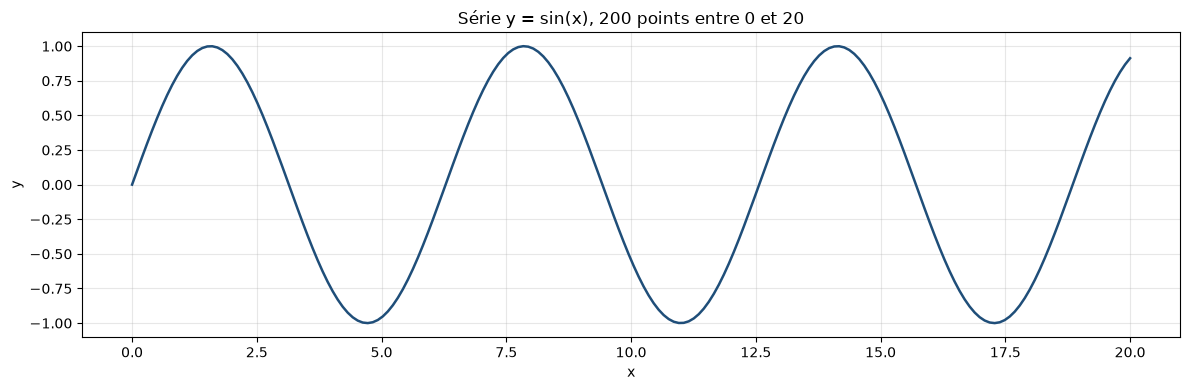

In [3]:
from src.evaluation import plot_series, save_figure

figure = plot_series(
    periode.numpy(),
    serie.numpy(),
    title="Série y = sin(x), 200 points entre 0 et 20",
    xlabel="x",
    ylabel="y",
)
save_figure(figure, ROOT / "outputs" / "figures" / "01_sinusoide.png")
plt.show()
        

## 2. RNN

Un RNN lit les 10 valeurs **dans l'ordre**. Il met à jour un état caché :

$$
h_t = \tanh(W_{ih} x_t + W_{hh} h_{t-1} + b)
$$

Ici `input_size=1` et `hidden_size=16`. La couche `Linear(16, 1)` ne voit que
le dernier état. Les dimensions sont donc :

$$
(B, 10, 1) \rightarrow (B, 10, 16) \rightarrow (B, 16) \rightarrow (B, 1)
$$

On entraîne 300 époques avec Adam, un pas de 0,01 et la MSE. Tout le lot
d'entraînement passe à chaque époque : il ne contient que 150 séquences.
        

In [4]:
from src.models import SimpleRNN
from src.training import predict, train_full_batch

set_seed(42)
rnn = SimpleRNN()
print("Paramètres du RNN :", count_parameters(rnn))
losses_rnn = train_full_batch(rnn, X_train, y_train, epochs=300, lr=0.01, device=device)
pred_rnn = predict(rnn, X_test)
erreur_rnn = torch.nn.functional.mse_loss(pred_rnn, y_test)
print(f"\nErreur de test : {erreur_rnn.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {pred_rnn[0].item():.4f}")
        

Paramètres du RNN : 321


Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504


Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103


Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025



Erreur de test : 0.000028
Valeur réelle  : -0.3639
Valeur prédite : -0.3601


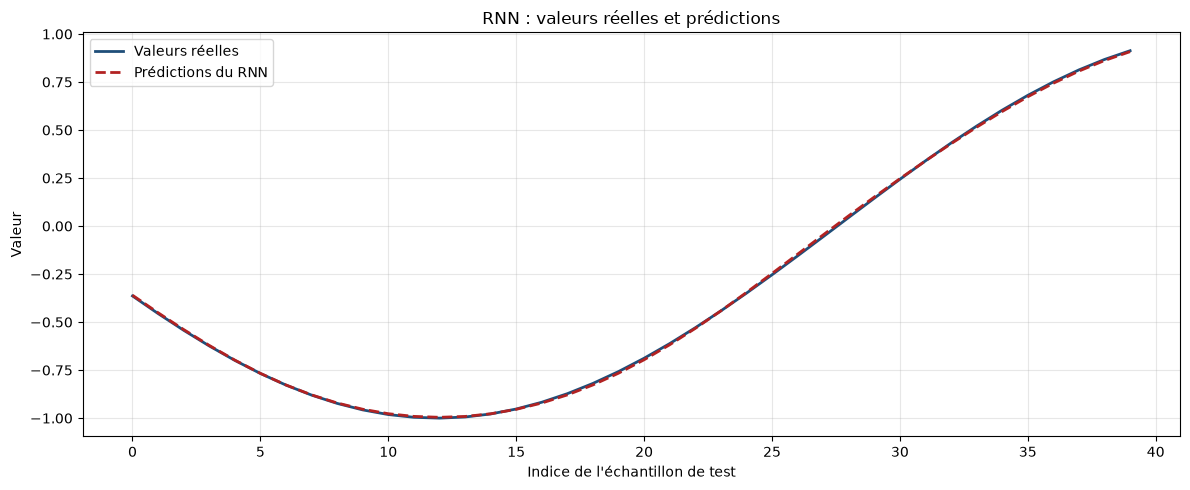

In [5]:
from src.evaluation import plot_forecast

figure = plot_forecast(
    y_test, pred_rnn,
    title="RNN : valeurs réelles et prédictions",
    pred_label="Prédictions du RNN",
)
save_figure(figure, ROOT / "outputs" / "figures" / "01_rnn_predictions.png")
plt.show()
        

## 3. LSTM

Le LSTM garde deux états. L'état caché `h_t` est la sortie visible.
L'état de cellule `c_t` est une mémoire interne contrôlée par trois portes.

$$
c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t
$$

$$
h_t = o_t \odot \tanh(c_t)
$$

La configuration du TP est `input_size=1`, `hidden_size=16`, `num_layers=1`,
`batch_first=True`, puis `Linear(16, 1)`. L'entraînement est le même que pour le RNN.
        

In [6]:
from src.models import SimpleLSTM

set_seed(42)
lstm = SimpleLSTM()
print("Paramètres du LSTM :", count_parameters(lstm))
losses_lstm = train_full_batch(lstm, X_train, y_train, epochs=300, lr=0.01, device=device)
pred_lstm = predict(lstm, X_test)
erreur_lstm = torch.nn.functional.mse_loss(pred_lstm, y_test)
print(f"\nErreur de test : {erreur_lstm.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {pred_lstm[0].item():.4f}")
        

Paramètres du LSTM : 1233


Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248
Epoch 150 | Erreur : 0.000043


Epoch 200 | Erreur : 0.000006
Epoch 250 | Erreur : 0.000004
Epoch 300 | Erreur : 0.000003



Erreur de test : 0.000003
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


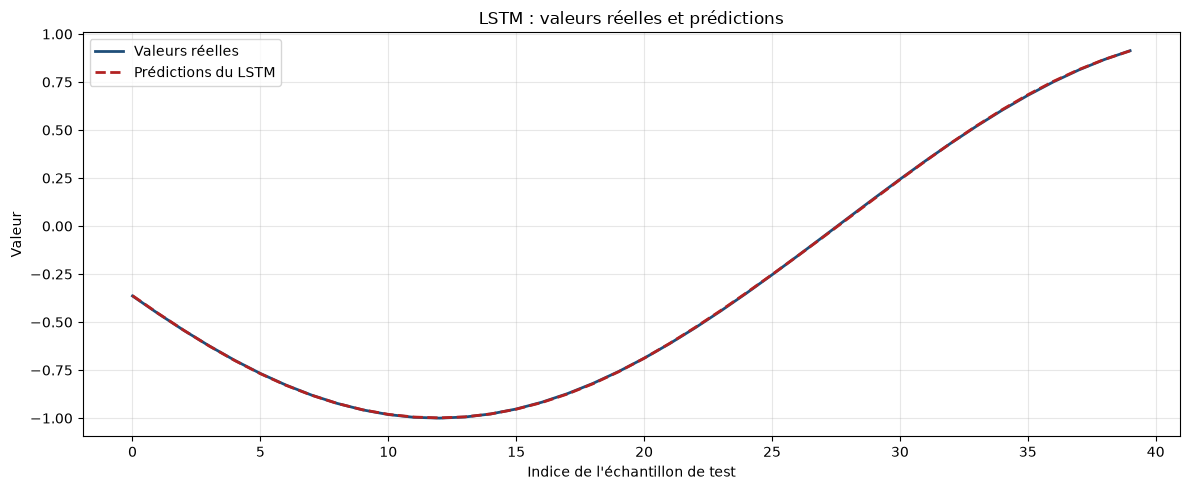

In [7]:
figure = plot_forecast(
    y_test, pred_lstm,
    title="LSTM : valeurs réelles et prédictions",
    pred_label="Prédictions du LSTM",
)
save_figure(figure, ROOT / "outputs" / "figures" / "01_lstm_predictions.png")
plt.show()
        

## 4. Mini-Transformer

Ce modèle ne relit pas la séquence pas à pas. Il projette chaque valeur de 1 vers 16,
ajoute une position apprise, puis applique **une** couche d'encodeur :

- `d_model=16`
- `nhead=2` (donc 8 composantes par tête)
- `dim_feedforward=32`
- `dropout=0`
- activation ReLU, qui est le réglage par défaut de `TransformerEncoderLayer`

La prédiction part de la dernière position. Aucun masque causal n'est posé :
les 10 entrées sont connues, et la 11e n'est jamais donnée au modèle.
        

In [8]:
from src.models import MiniTransformer

set_seed(42)
transformer = MiniTransformer(longueur_max=10)
print("Paramètres du Transformer :", count_parameters(transformer))
losses_transformer = train_full_batch(
    transformer, X_train, y_train, epochs=300, lr=0.01, device=device
)
pred_transformer = predict(transformer, X_test)
erreur_transformer = torch.nn.functional.mse_loss(pred_transformer, y_test)
print(f"\nErreur de test : {erreur_transformer.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {pred_transformer[0].item():.4f}")
        

Paramètres du Transformer : 2433


Epoch  50 | Erreur : 0.001504
Epoch 100 | Erreur : 0.000110


Epoch 150 | Erreur : 0.000026
Epoch 200 | Erreur : 0.000012


Epoch 250 | Erreur : 0.000007
Epoch 300 | Erreur : 0.000004



Erreur de test : 0.000006
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


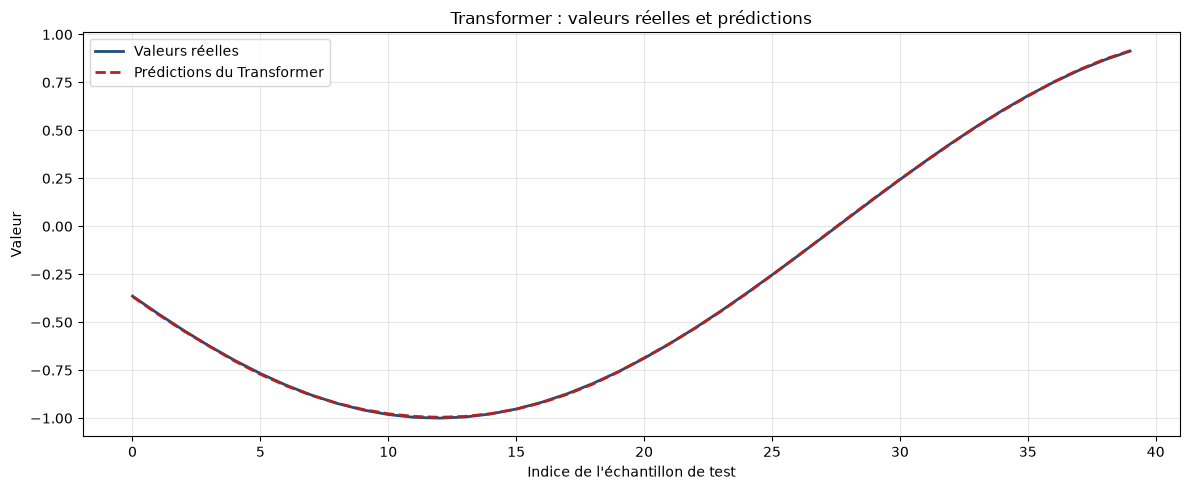

In [9]:
figure = plot_forecast(
    y_test, pred_transformer,
    title="Transformer : valeurs réelles et prédictions",
    pred_label="Prédictions du Transformer",
)
save_figure(figure, ROOT / "outputs" / "figures" / "01_transformer_predictions.png")
plt.show()
        

## 5. Comparaison sur le test

La MSE moyenne les carrés des erreurs. La MAE moyenne les valeurs absolues.
La RMSE est la racine de la MSE : elle s'exprime dans la même unité que `y`,
ici sans unité, puisque le sinus est déjà entre -1 et 1.

Ces trois nombres sont recalculés par scikit-learn sur les 40 prédictions de test.
Ils ne sont pas recopiés à la main.
        

                 mse      mae     rmse
modèle                                
RNN         0.000028 0.004562 0.005256
LSTM        0.000003 0.001355 0.001582
Transformer 0.000006 0.002041 0.002349


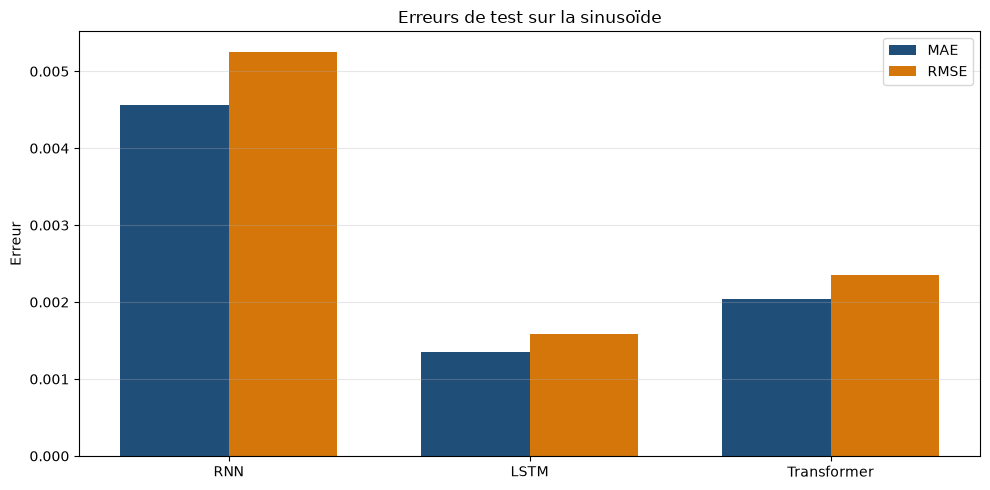

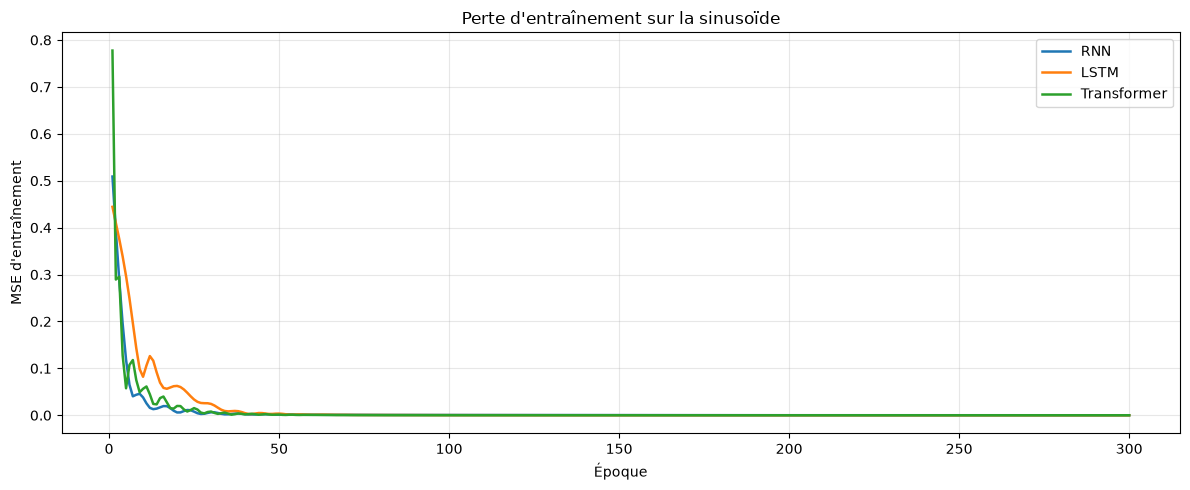

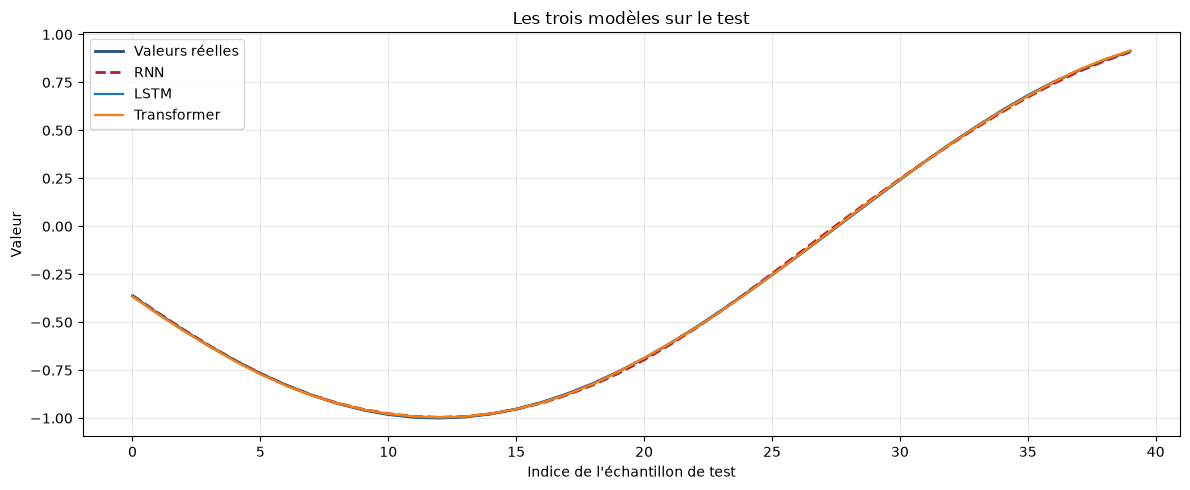

RMSE la plus basse sur ce test : LSTM (0.001582).
Cette série est courte et très régulière : une bonne RMSE n'annonce pas
le même classement sur la consommation électrique.


In [10]:
from src.evaluation import plot_loss_curves, plot_metric_bars, regression_scores, save_json

resultats = {
    "RNN": regression_scores(y_test, pred_rnn),
    "LSTM": regression_scores(y_test, pred_lstm),
    "Transformer": regression_scores(y_test, pred_transformer),
}
tableau = pd.DataFrame(resultats).T
tableau.index.name = "modèle"
print(tableau.to_string(float_format=lambda valeur: f"{valeur:.6f}"))
save_json(ROOT / "outputs" / "metrics" / "01_sinusoide.json", {
    "device": str(device),
    "metriques": resultats,
    "perte_finale_train": {
        "RNN": losses_rnn[-1],
        "LSTM": losses_lstm[-1],
        "Transformer": losses_transformer[-1],
    },
})

figure = plot_metric_bars(resultats, "Erreurs de test sur la sinusoïde")
save_figure(figure, ROOT / "outputs" / "figures" / "01_comparaison_barres.png")
plt.show()

figure = plot_loss_curves(
    {"RNN": losses_rnn, "LSTM": losses_lstm, "Transformer": losses_transformer},
    "Perte d'entraînement sur la sinusoïde",
)
save_figure(figure, ROOT / "outputs" / "figures" / "01_pertes.png")
plt.show()

figure = plot_forecast(y_test, pred_rnn, title="Les trois modèles sur le test", pred_label="RNN")
axis = figure.axes[0]
axis.plot(pred_lstm.numpy().reshape(-1), label="LSTM", linewidth=1.6)
axis.plot(pred_transformer.numpy().reshape(-1), label="Transformer", linewidth=1.6)
axis.legend()
save_figure(figure, ROOT / "outputs" / "figures" / "01_comparaison_courbes.png")
plt.show()

meilleur = min(resultats, key=lambda nom: resultats[nom]["rmse"])
print(f"RMSE la plus basse sur ce test : {meilleur} ({resultats[meilleur]['rmse']:.6f}).")
print("Cette série est courte et très régulière : une bonne RMSE n'annonce pas")
print("le même classement sur la consommation électrique.")
        

## Ce qu'il faut retenir pour l'oral

- Le RNN résume la fenêtre dans un état qui avance dans le temps.
- Le LSTM ajoute une mémoire de cellule et des portes, donc plus de paramètres.
- Le Transformer relie les positions par l'attention et a besoin d'une information de position.
- Sur cette sinusoïde, les trois courbes de test doivent être lues avec le tableau,
  pas avec une impression visuelle seule.
- Le test est chronologique : ce sont les 40 dernières fenêtres, pas un tirage aléatoire.
        

## Résultats mesurés de cette exécution

Périphérique : MPS. Les 40 fenêtres de test donnent :

| Modèle | MSE | MAE | RMSE |
|---|---:|---:|---:|
| RNN | 0,0000276 | 0,004562 | 0,005256 |
| LSTM | 0,00000250 | 0,001355 | 0,001582 |
| Transformer | 0,00000552 | 0,002041 | 0,002349 |

Le LSTM a la RMSE la plus basse sur cette sinusoïde. Les trois erreurs restent très petites. Ce classement ne dit pas lequel sera le meilleur sur la consommation électrique.